In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data/creditcard.csv')

In [3]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [4]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.duplicated().sum()

np.int64(1081)

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

In [7]:
df['Time'].nunique()

124592

In [8]:
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [9]:
df['Amount'].value_counts()

Amount
1.00      13566
1.98       6044
0.89       4871
9.99       4738
15.00      3280
          ...  
787.95        1
405.09        1
381.05        1
337.54        1
95.63         1
Name: count, Length: 32767, dtype: int64

In [10]:
df['Amount'].nunique()

32767

In [11]:
df['Hour'] = (df['Time'] // 3600) % 24
df['Log_Amount'] = np.log1p(df['Amount'])

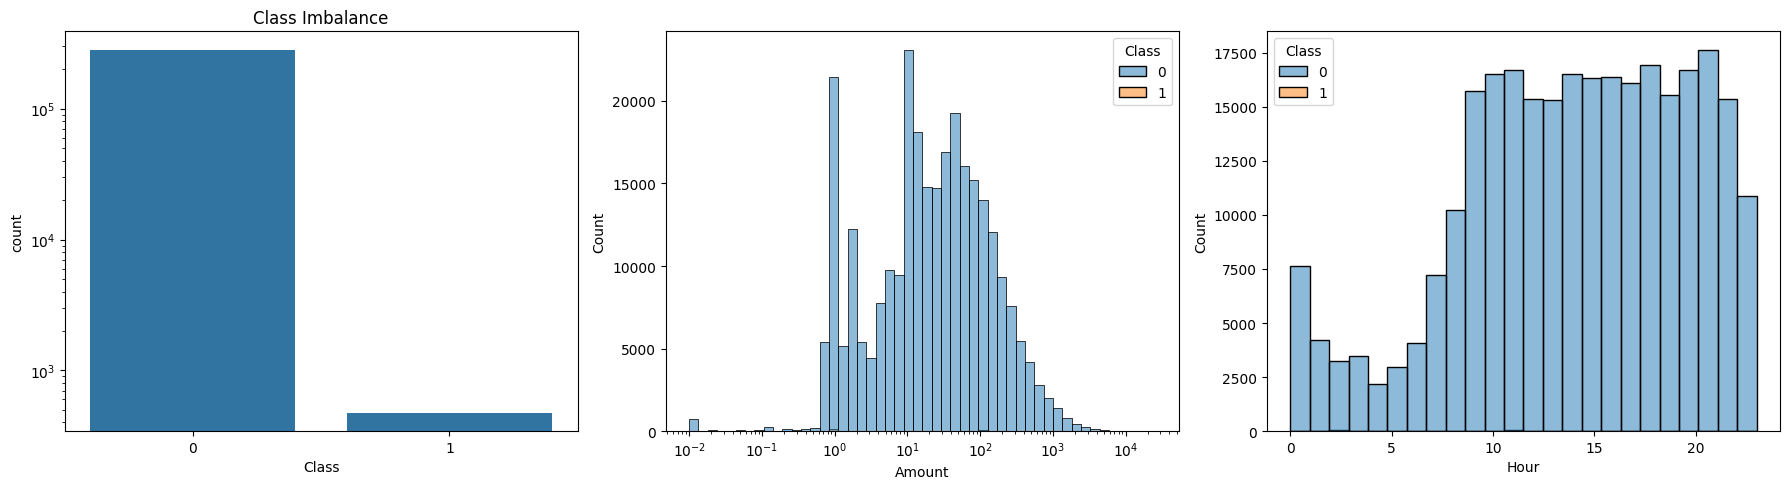

In [12]:
fig,axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(x='Class', data=df, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Class Imbalance')
sns.histplot(data=df, x='Amount', hue='Class', bins=50, log_scale=(True, False), ax=axes[1])
sns.histplot(data=df, x='Hour', hue='Class', bins=24, ax=axes[2])
plt.tight_layout()
plt.savefig('plots/eda_plots.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Data columns (total 33 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Time        283726 non-null  float64
 1   V1          283726 non-null  float64
 2   V2          283726 non-null  float64
 3   V3          283726 non-null  float64
 4   V4          283726 non-null  float64
 5   V5          283726 non-null  float64
 6   V6          283726 non-null  float64
 7   V7          283726 non-null  float64
 8   V8          283726 non-null  float64
 9   V9          283726 non-null  float64
 10  V10         283726 non-null  float64
 11  V11         283726 non-null  float64
 12  V12         283726 non-null  float64
 13  V13         283726 non-null  float64
 14  V14         283726 non-null  float64
 15  V15         283726 non-null  float64
 16  V16         283726 non-null  float64
 17  V17         283726 non-null  float64
 18  V18         283726 non-null  float64
 19  V19         2

In [14]:
df.describe()['Amount']

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

In [15]:
df['Class'].value_counts(normalize=True)

Class
0    0.998333
1    0.001667
Name: proportion, dtype: float64

In [16]:
X = df.drop(['Class', 'Amount', 'Time'], axis=1)
y = df['Class']

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
X_train.to_pickle('artifacts/X_train.pkl')
X_test.to_pickle('artifacts/X_test.pkl')
y_train.to_pickle('artifacts/y_train.pkl')
y_test.to_pickle('artifacts/y_test.pkl')

In [20]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Data columns (total 30 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   V1          283726 non-null  float64
 1   V2          283726 non-null  float64
 2   V3          283726 non-null  float64
 3   V4          283726 non-null  float64
 4   V5          283726 non-null  float64
 5   V6          283726 non-null  float64
 6   V7          283726 non-null  float64
 7   V8          283726 non-null  float64
 8   V9          283726 non-null  float64
 9   V10         283726 non-null  float64
 10  V11         283726 non-null  float64
 11  V12         283726 non-null  float64
 12  V13         283726 non-null  float64
 13  V14         283726 non-null  float64
 14  V15         283726 non-null  float64
 15  V16         283726 non-null  float64
 16  V17         283726 non-null  float64
 17  V18         283726 non-null  float64
 18  V19         283726 non-null  float64
 19  V20         2

In [21]:
y.info()

<class 'pandas.Series'>
RangeIndex: 283726 entries, 0 to 283725
Series name: Class
Non-Null Count   Dtype
--------------   -----
283726 non-null  int64
dtypes: int64(1)
memory usage: 2.2 MB
